
## Task 3: Object Recognition

### Aim
To explore and compare Haar Cascade and YOLO object detection methods using a portrait image.

### Methods
- **Haar Cascade:** Uses trained visual patterns to detect specific features, commonly faces.
- **YOLO:** Detects and classifies objects using a trained deep learning model.

The results will be visualized using bounding boxes and compared to understand each method's capabilities and limitations.


Image loaded successfully.
Image dimensions: 1080 x 1469


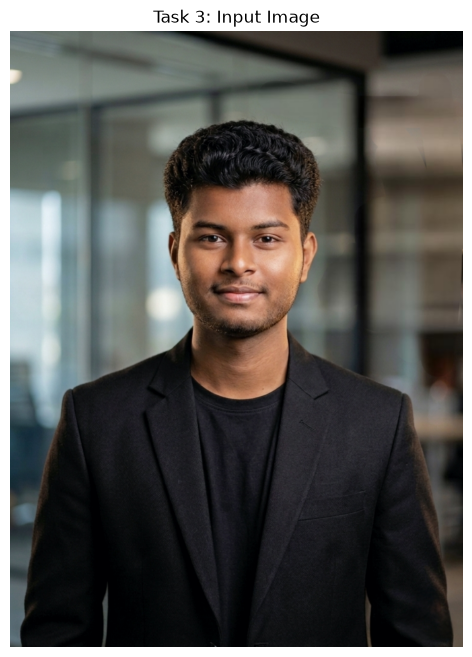

In [21]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

PROJECT_DIR = Path(r"D:\Computer Vision Project")
INPUT_DIR = PROJECT_DIR / "input"
OUTPUT_DIR = PROJECT_DIR / "outputs"
MODEL_DIR = PROJECT_DIR / "models"

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

IMAGE_PATH = INPUT_DIR / "portrait.jpg"

image = cv2.imread(str(IMAGE_PATH))

if image is None:
    raise FileNotFoundError(
        f"Could not load image: {IMAGE_PATH}\n"
        "Check that portrait.jpg is inside the input folder."
    )

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("Image loaded successfully.")
print("Image dimensions:", image.shape[1], "x", image.shape[0])

plt.figure(figsize=(8, 8))
plt.imshow(image_rgb)
plt.title("Task 3: Input Image")
plt.axis("off")
plt.show()


### Image Preparation
The image is loaded using OpenCV and displayed using Matplotlib. OpenCV uses BGR colour order, so the image is converted to RGB for correct display. The original image will be used for both detection experiments.



## 2. Viola-Jones Haar Cascade

Haar Cascade is a traditional computer vision method that uses trained visual patterns to detect faces. We will apply a pretrained frontal-face classifier to the portrait and visualize detected regions using bounding boxes.


In [22]:
# Load OpenCV's pretrained frontal-face classifier
cascade_path = (
    cv2.data.haarcascades
    + "haarcascade_frontalface_default.xml"
)

face_cascade = cv2.CascadeClassifier(cascade_path)

print("Cascade file:", cascade_path)
print("Classifier loaded:", not face_cascade.empty())

Cascade file: d:\Computer Vision Project\venv\Lib\site-packages\cv2\data\haarcascade_frontalface_default.xml
Classifier loaded: False


In [23]:
from urllib.request import urlretrieve

cascade_path = str(
    MODEL_DIR / "haarcascade_frontalface_default.xml"
)

url = (
    "https://raw.githubusercontent.com/opencv/opencv/4.x/"
    "data/haarcascades/haarcascade_frontalface_default.xml"
)

if not Path(cascade_path).exists():
    urlretrieve(url, cascade_path)

face_cascade = cv2.CascadeClassifier(cascade_path)

if face_cascade.empty():
    raise RuntimeError("Haar Cascade model could not be loaded.")

print("Haar Cascade model loaded successfully.")

Haar Cascade model loaded successfully.


Faces detected: 1


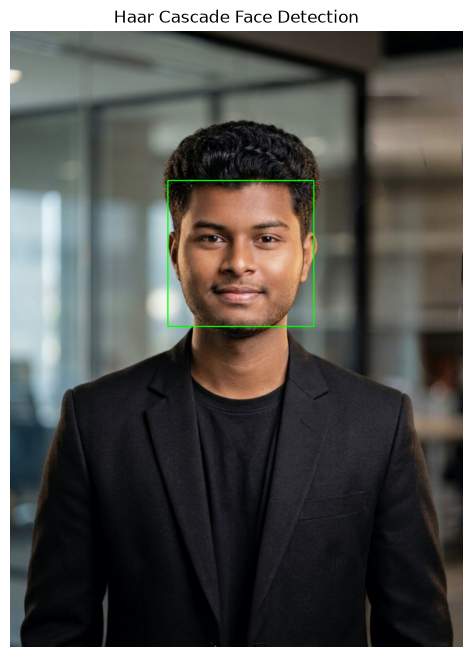

Saved: outputs/haar_cascade_result.jpg


In [24]:
# Convert the portrait to grayscale for face detection
gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# Detect face-like regions
faces = face_cascade.detectMultiScale(
    gray,
    scaleFactor=1.1,
    minNeighbors=5,
    minSize=(30, 30)
)

# Draw bounding boxes around detected faces
haar_result = image.copy()

for (x, y, w, h) in faces:
    cv2.rectangle(
        haar_result,
        (x, y),
        (x + w, y + h),
        (0, 255, 0),
        2
    )

print("Faces detected:", len(faces))

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(haar_result, cv2.COLOR_BGR2RGB))
plt.title("Haar Cascade Face Detection")
plt.axis("off")
plt.show()

cv2.imwrite(
    str(OUTPUT_DIR / "haar_cascade_result.jpg"),
    haar_result
)

print("Saved: outputs/haar_cascade_result.jpg")


### Observation
The green rectangles indicate regions identified as faces by the Haar Cascade classifier. Detection performance depends on face size, lighting, orientation, and image quality.


## 3. YOLO Object Detection

YOLO is a deep-learning object detector that identifies and classifies objects in an image. We use a pretrained model and compare its detections with the Haar Cascade results.

In [25]:
from ultralytics import YOLO

# Load a pretrained YOLO model
yolo_model = YOLO("yolov8n.pt")

print("YOLO model loaded successfully.")

YOLO model loaded successfully.


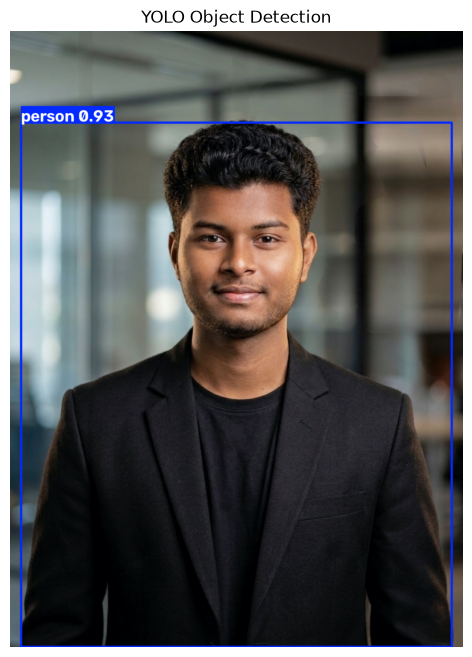

Saved: outputs/yolo_result.jpg
Objects detected: 1


In [26]:
# Run YOLO on the original image
results = yolo_model.predict(
    source=str(IMAGE_PATH),
    conf=0.25,
    save=False,
    verbose=False
)

# Display the detection result
yolo_result = results[0].plot()

plt.figure(figsize=(8, 8))
plt.imshow(cv2.cvtColor(yolo_result, cv2.COLOR_BGR2RGB))
plt.title("YOLO Object Detection")
plt.axis("off")
plt.show()

# Save the result
cv2.imwrite(
    str(OUTPUT_DIR / "yolo_result.jpg"),
    yolo_result
)

print("Saved: outputs/yolo_result.jpg")
print("Objects detected:", len(results[0].boxes))

### Observation
YOLO displays bounding boxes with predicted class labels and confidence scores. Its detections can be compared with Haar Cascade, which is designed specifically for face detection in this experiment.

## 4. Comparison of Detection Methods

Haar Cascade and YOLO are compared based on their detection results, bounding-box accuracy, and ability to identify objects.

- **Haar Cascade:** Focuses on detecting frontal faces using a trained cascade classifier.
- **YOLO:** Detects objects and assigns class labels and confidence scores.

The results depend on the input image and the capabilities of each pretrained model.

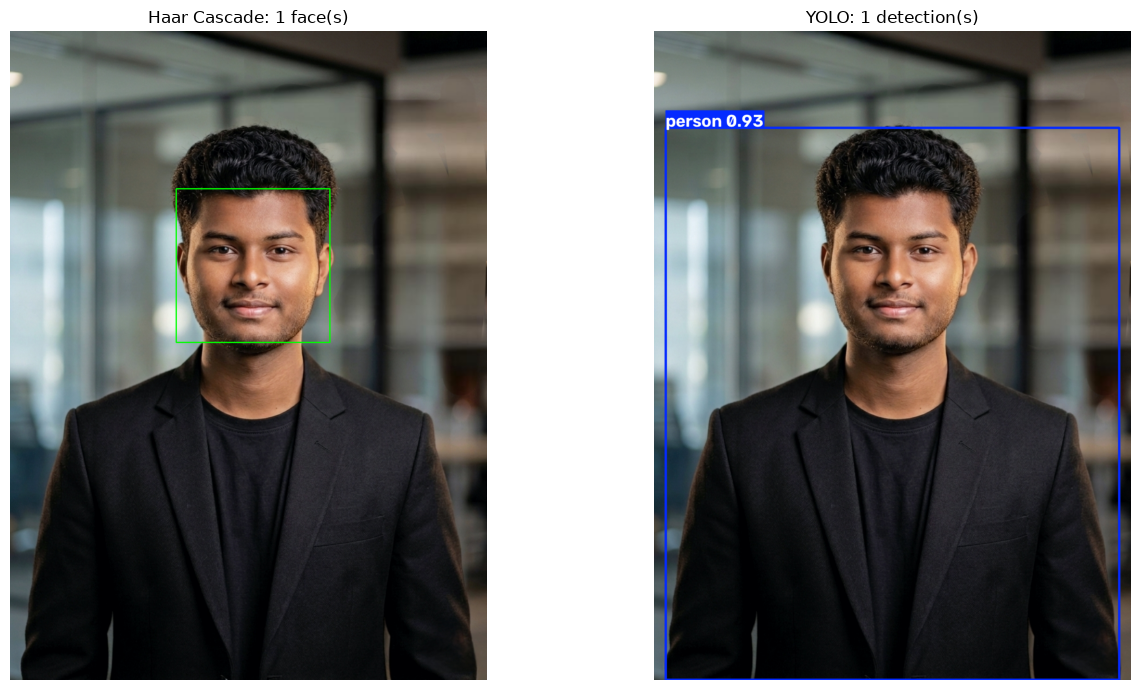

Haar Cascade detections: 1
YOLO detections: 1


In [27]:
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

axes[0].imshow(cv2.cvtColor(haar_result, cv2.COLOR_BGR2RGB))
axes[0].set_title(f"Haar Cascade: {len(faces)} face(s)")
axes[0].axis("off")

axes[1].imshow(cv2.cvtColor(yolo_result, cv2.COLOR_BGR2RGB))
axes[1].set_title(f"YOLO: {len(results[0].boxes)} detection(s)")
axes[1].axis("off")

plt.tight_layout()
plt.show()

print("Haar Cascade detections:", len(faces))
print("YOLO detections:", len(results[0].boxes))